<a href="https://colab.research.google.com/github/Mayureshj111/vizwiz-answerability-fusion/blob/main/VizWiz_Fusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Flagging Unanswerable Visual Questions with Image–Text Fusion
Mayuresh Joshi (a1985039). Predicts whether a VizWiz photo–question pair is unanswerable, comparing unimodal baselines, late/early/cross-attention/gated fusion, and a CLIP reference.

**To run:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all.

## 1. Setup: mount Drive, check GPU

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
SAVE = '/content/drive/MyDrive/vizwiz'
os.makedirs(SAVE, exist_ok=True)

import torch
print('GPU:', torch.cuda.get_device_name(0))

Mounted at /content/drive
GPU: Tesla T4


## 2. Download annotations

In [2]:
!wget -q https://vizwiz.cs.colorado.edu/VizWiz_final/vqa_data/Annotations.zip
!unzip -q Annotations.zip -d data
!ls data
!ls data/*

test.json  train.json  val.json
data/test.json	data/train.json  data/val.json


## 3. Download images

In [3]:
!wget -q --show-progress https://vizwiz.cs.colorado.edu/VizWiz_final/images/train.zip
!wget -q --show-progress https://vizwiz.cs.colorado.edu/VizWiz_final/images/val.zip
!unzip -q train.zip -d data
!unzip -q val.zip -d data
!rm train.zip val.zip
!ls data
!ls data/train | wc -l
!ls data/val | wc -l

train.zip           100%[===================>]  10.52G  72.3MB/s    in 2m 56s  
val.zip             100%[===================>]   3.25G  91.8MB/s    in 50s     
test.json  train  train.json  val  val.json
23954
7750


## 4. Load labels and make splits

In [4]:
import json, os, pandas as pd
from sklearn.model_selection import train_test_split

def load(split):
    df = pd.DataFrame(json.load(open(f'data/{split}.json')))
    df['label'] = 1 - df['answerable']          # 1 = unanswerable
    df['soft'] = df['answers'].apply(
        lambda a: sum(x['answer'] == 'unanswerable' for x in a) / len(a))
    df['path'] = f'data/{split}/' + df['image']
    return df

full_train, test = load('train'), load('val')

# check every image exists
print('missing train:', (~full_train.path.apply(os.path.exists)).sum())
print('missing test :', (~test.path.apply(os.path.exists)).sum())

# hold out 15% of train for tuning (official val = our test)
train, dev = train_test_split(full_train, test_size=0.15,
                              stratify=full_train['label'], random_state=42)

for name, d in [('train', train), ('dev', dev), ('test', test)]:
    print(name, len(d), 'unanswerable:', round(d.label.mean(), 3))

train.to_pickle(f'{SAVE}/train.pkl')
dev.to_pickle(f'{SAVE}/dev.pkl')
test.to_pickle(f'{SAVE}/test.pkl')

missing train: 0
missing test : 0
train 17444 unanswerable: 0.27
dev 3079 unanswerable: 0.27
test 4319 unanswerable: 0.321


## 5. Data quality checks

answerable but >=3/10 unanswerable votes: 0.167
pairs with a repeated question: 0.579
question
what is this          3066
what color is this     424
what is it             296
what is this item      268
what does this say     225
Name: count, dtype: int64


100%|██████████| 4319/4319 [01:04<00:00, 66.54it/s]


median sharpness  unanswerable: 196.4  answerable: 292.9
Mann-Whitney p = 6.294700769165046e-92


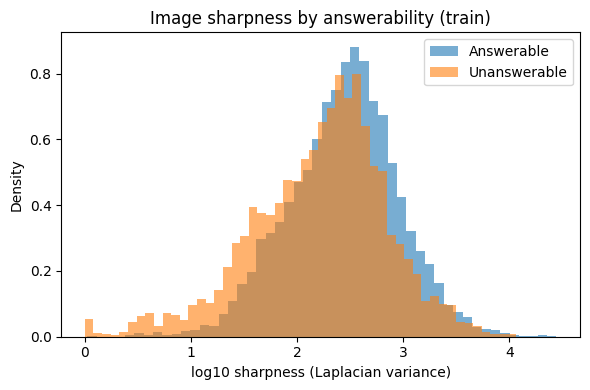

In [5]:
import numpy as np, cv2
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from tqdm import tqdm

train, dev = train.copy(), dev.copy()

# 1. Label noise: answerable pairs where 3+ of 10 workers said "unanswerable"
ans = full_train[full_train.label == 0]
print('answerable but >=3/10 unanswerable votes:', round((ans.soft >= 0.3).mean(), 3))

# 2. Repeated questions
q = full_train.question.str.lower().str.strip().str.rstrip('?').str.strip()
counts = q.value_counts()
print('pairs with a repeated question:', round((q.map(counts) > 1).mean(), 3))
print(counts.head(5))

# 3. Image sharpness (blur), higher = sharper
def sharpness(p):
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (512, 512))
    return cv2.Laplacian(img, cv2.CV_64F).var()

for d in (train, dev, test):
    d['sharp'] = [sharpness(p) for p in tqdm(d.path)]

u = train[train.label == 1].sharp
a = train[train.label == 0].sharp
print('median sharpness  unanswerable:', round(u.median(), 1), ' answerable:', round(a.median(), 1))
print('Mann-Whitney p =', mannwhitneyu(u, a).pvalue)

# Figure for report
plt.figure(figsize=(6, 4))
plt.hist(np.log10(a + 1), bins=50, alpha=0.6, label='Answerable', density=True)
plt.hist(np.log10(u + 1), bins=50, alpha=0.6, label='Unanswerable', density=True)
plt.xlabel('log10 sharpness (Laplacian variance)')
plt.ylabel('Density')
plt.title('Image sharpness by answerability (train)')
plt.legend()
plt.tight_layout()
plt.savefig(f'{SAVE}/fig_sharpness.png', dpi=200)
plt.show()

# Save updated splits
train.to_pickle(f'{SAVE}/train.pkl')
dev.to_pickle(f'{SAVE}/dev.pkl')
test.to_pickle(f'{SAVE}/test.pkl')

## 6. Feature extraction (ViT + BERT)

In [7]:
import torch, time, numpy as np
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from transformers import ViTModel, ViTImageProcessor, BertModel, BertTokenizer

device = 'cuda'
proc = ViTImageProcessor.from_pretrained('google/vit-base-patch16-224-in21k')
vit  = ViTModel.from_pretrained('google/vit-base-patch16-224-in21k').to(device).eval().half()
tok  = BertTokenizer.from_pretrained('bert-base-uncased')
bert = BertModel.from_pretrained('bert-base-uncased').to(device).eval().half()

class Imgs(Dataset):
    def __init__(s, paths): s.p = list(paths)
    def __len__(s): return len(s.p)
    def __getitem__(s, i):
        img = ImageOps.exif_transpose(Image.open(s.p[i])).convert('RGB')   # fix rotation
        return proc(img, return_tensors='pt')['pixel_values'][0]           # 224x224, no crop

@torch.no_grad()
def img_feats(paths):
    out = []
    for x in tqdm(DataLoader(Imgs(paths), batch_size=64, num_workers=2)):
        h = vit(pixel_values=x.to(device).half()).last_hidden_state        # (B,197,768)
        cls, patch = h[:, :1], h[:, 1:]
        grid = patch.reshape(-1, 14, 14, 768).permute(0, 3, 1, 2)
        pooled = F.avg_pool2d(grid, 2).flatten(2).transpose(1, 2)          # (B,49,768)
        out.append(torch.cat([cls, pooled], 1).cpu())                      # (B,50,768)
    return torch.cat(out).numpy().astype(np.float16)

@torch.no_grad()
def txt_feats(qs):
    qs, H, M = list(qs), [], []
    for i in tqdm(range(0, len(qs), 256)):
        t = tok(qs[i:i+256], padding='max_length', truncation=True,
                max_length=32, return_tensors='pt').to(device)
        H.append(bert(**t).last_hidden_state.cpu())                        # (B,32,768)
        M.append(t['attention_mask'].cpu())
    return torch.cat(H).numpy().astype(np.float16), torch.cat(M).numpy()

start = time.time()
for name, d in [('train', train), ('dev', dev), ('test', test)]:
    np.save(f'{SAVE}/{name}_img.npy', img_feats(d.path))
    h, m = txt_feats(d.question)
    np.save(f'{SAVE}/{name}_txt.npy', h)
    np.save(f'{SAVE}/{name}_mask.npy', m)
print(f'Extraction time: {(time.time()-start)/60:.1f} min')
print('Peak GPU memory:', round(torch.cuda.max_memory_allocated()/1e9, 2), 'GB')

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
100%|██████████| 17/17 [00:02<00:00,  8.11it/s]


Extraction time: 11.8 min
Peak GPU memory: 0.7 GB


## 7. Training setup

In [8]:
import torch.nn as nn, random, pickle
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, accuracy_score

# Load cached features onto the GPU
def load_split(name, df):
    return dict(img=torch.tensor(np.load(f'{SAVE}/{name}_img.npy')).to(device),
                txt=torch.tensor(np.load(f'{SAVE}/{name}_txt.npy')).to(device),
                mask=torch.tensor(np.load(f'{SAVE}/{name}_mask.npy')).to(device),
                soft=torch.tensor(df.soft.values, dtype=torch.float32).to(device),
                y=df.label.values)
D = {n: load_split(n, d) for n, d in [('train', train), ('dev', dev), ('test', test)]}

# Helpers
def tmean(t, m):                      # mean over real words, ignoring padding
    m = m.unsqueeze(-1).float()
    return (t * m).sum(1) / m.sum(1).clamp(min=1)

def mlp(d_in, d_h=256, p=0.3):
    return nn.Sequential(nn.LayerNorm(d_in), nn.Linear(d_in, d_h), nn.GELU(),
                         nn.Dropout(p), nn.Linear(d_h, 1))

@torch.no_grad()
def get_logits(model, S, bs=1024):
    model.eval()
    return torch.cat([model(S['img'][i:i+bs].float(), S['txt'][i:i+bs].float(), S['mask'][i:i+bs])
                      for i in range(0, len(S['y']), bs)])

def best_thr(y, p):                   # threshold tuned on dev for macro-F1
    ts = np.linspace(0.05, 0.95, 91)
    return ts[np.argmax([f1_score(y, p >= t, average='macro') for t in ts])]

def metrics(y, p, t):
    return dict(macro_f1=f1_score(y, p >= t, average='macro'), auroc=roc_auc_score(y, p),
                auprc=average_precision_score(y, p), acc=accuracy_score(y, p >= t))

# Training loop: weighted soft-label loss, early stopping on dev AUROC
def train_model(make, seed, lr=1e-3, epochs=30, bs=128, patience=4):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = make().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    T = D['train']; n = len(T['y'])
    pw = torch.tensor((1 - T['y'].mean()) / T['y'].mean(), device=device)
    lossf = nn.BCEWithLogitsLoss(pos_weight=pw)
    hist, best_state, best_auc, bad = [], None, -1, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, device=device); tot = 0
        for i in range(0, n, bs):
            idx = perm[i:i+bs]
            loss = lossf(model(T['img'][idx].float(), T['txt'][idx].float(), T['mask'][idx]), T['soft'][idx])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        ld = get_logits(model, D['dev']); lt = get_logits(model, T)
        h = dict(epoch=ep + 1, train_loss=tot / n, dev_loss=lossf(ld, D['dev']['soft']).item(),
                 train_auc=roc_auc_score(T['y'], torch.sigmoid(lt).cpu()),
                 dev_auc=roc_auc_score(D['dev']['y'], torch.sigmoid(ld).cpu()))
        hist.append(h)
        if h['dev_auc'] > best_auc:
            best_auc, bad = h['dev_auc'], 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    p = {s: torch.sigmoid(get_logits(model, D[s])).cpu().numpy() for s in D}
    t = best_thr(D['dev']['y'], p['dev'])
    res = metrics(D['test']['y'], p['test'], t)
    res['train_f1'] = f1_score(D['train']['y'], p['train'] >= t, average='macro')
    res['threshold'], res['epochs'] = t, len(hist)
    res['params'] = sum(x.numel() for x in model.parameters())
    return res, hist, p['test'], model

# Run several seeds and save everything to Drive
results, histories, test_probs = [], {}, {}
def run(name, make, lr=1e-3, seeds=(0, 1, 2)):
    for s in seeds:
        t0 = time.time()
        res, hist, pte, _ = train_model(make, s, lr)
        res.update(model=name, seed=s, secs=round(time.time() - t0, 1))
        results.append(res); histories[(name, s)] = hist; test_probs[(name, s)] = pte
    df = pd.DataFrame([r for r in results if r['model'] == name])
    print(name); print(df[['macro_f1', 'auroc', 'auprc', 'train_f1', 'epochs', 'secs']].agg(['mean', 'std']).round(3))
    pickle.dump((results, histories, test_probs), open(f'{SAVE}/results.pkl', 'wb'))

print('Ready. Train size:', len(D['train']['y']))

Ready. Train size: 17444


## 8. Unimodal baselines

In [9]:
class QOnly(nn.Module):               # question only
    def __init__(s): super().__init__(); s.f = mlp(768)
    def forward(s, img, txt, mask): return s.f(tmean(txt, mask)).squeeze(-1)

class IOnly(nn.Module):               # image only
    def __init__(s): super().__init__(); s.f = mlp(768)
    def forward(s, img, txt, mask): return s.f(img.mean(1)).squeeze(-1)

run('Question-only', QOnly)
run('Image-only', IOnly)

Question-only
      macro_f1  auroc  auprc  train_f1  epochs   secs
mean     0.650  0.729  0.552     0.717  15.667  6.533
std      0.001  0.001  0.000     0.008   1.155  1.305
Image-only
      macro_f1  auroc  auprc  train_f1  epochs   secs
mean     0.696  0.772  0.617     0.842   8.000  3.067
std      0.004  0.004  0.006     0.038   1.732  0.379


## 9. Fusion models

In [10]:
# 1. Early fusion: concatenate pooled features, then MLP
class Early(nn.Module):
    def __init__(s): super().__init__(); s.f = mlp(1536)
    def forward(s, img, txt, mask):
        return s.f(torch.cat([img.mean(1), tmean(txt, mask)], -1)).squeeze(-1)

# 2. Cross-attention: question tokens attend to image regions and vice versa
class CrossAttn(nn.Module):
    def __init__(s, d=192, heads=4, p=0.2):
        super().__init__()
        s.pi, s.pt = nn.Linear(768, d), nn.Linear(768, d)
        s.t2i = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        s.i2t = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        s.ni, s.nt = nn.LayerNorm(d), nn.LayerNorm(d)
        s.f = mlp(2 * d)
    def forward(s, img, txt, mask):
        i, t = s.pi(img), s.pt(txt)
        pad = ~mask.bool()
        t2 = s.nt(t + s.t2i(t, i, i)[0])                       # text looks at image
        i2 = s.ni(i + s.i2t(i, t, t, key_padding_mask=pad)[0])  # image looks at text
        return s.f(torch.cat([tmean(t2, mask), i2.mean(1)], -1)).squeeze(-1)

# 3. Gated fusion (GMU) with modality dropout
class Gated(nn.Module):
    def __init__(s, d=256, pdrop=0.15):
        super().__init__()
        s.hi, s.ht = nn.Linear(768, d), nn.Linear(768, d)
        s.z = nn.Linear(1536, d)
        s.f = mlp(d); s.pd = pdrop; s.last_z = None
    def forward(s, img, txt, mask):
        xi, xt = img.mean(1), tmean(txt, mask)
        if s.training and s.pd > 0:                             # randomly hide one modality
            r = torch.rand(xi.size(0), 1, device=xi.device)
            xi = xi * (r >= s.pd).float()
            xt = xt * ((r < s.pd) | (r >= 2 * s.pd)).float()
        z = torch.sigmoid(s.z(torch.cat([xi, xt], -1)))        # weight on image
        s.last_z = z.mean(1).detach()
        h = z * torch.tanh(s.hi(xi)) + (1 - z) * torch.tanh(s.ht(xt))
        return s.f(h).squeeze(-1)

# 4. Late fusion: train unimodal models, weighted average of probabilities (weight tuned on dev)
def run_late(seeds=(0, 1, 2)):
    for s in seeds:
        t0, P = time.time(), {}
        for nm, mk in [('q', QOnly), ('i', IOnly)]:
            _, _, _, m = train_model(mk, s)
            P[nm] = {sp: torch.sigmoid(get_logits(m, D[sp])).cpu().numpy() for sp in D}
        ws = np.linspace(0, 1, 21)
        w = ws[np.argmax([roc_auc_score(D['dev']['y'], w * P['i']['dev'] + (1 - w) * P['q']['dev']) for w in ws])]
        p = {sp: w * P['i'][sp] + (1 - w) * P['q'][sp] for sp in D}
        t = best_thr(D['dev']['y'], p['dev'])
        res = metrics(D['test']['y'], p['test'], t)
        res.update(train_f1=f1_score(D['train']['y'], p['train'] >= t, average='macro'),
                   threshold=t, epochs=np.nan, params=np.nan, w_img=w,
                   model='Late fusion', seed=s, secs=round(time.time() - t0, 1))
        results.append(res); test_probs[('Late fusion', s)] = p['test']
    df = pd.DataFrame([r for r in results if r['model'] == 'Late fusion'])
    print('Late fusion (image weight:', df.w_img.tolist(), ')')
    print(df[['macro_f1', 'auroc', 'auprc', 'train_f1', 'secs']].agg(['mean', 'std']).round(3))
    pickle.dump((results, histories, test_probs), open(f'{SAVE}/results.pkl', 'wb'))

run_late()
run('Early fusion', Early)
run('Cross-attention', CrossAttn, lr=3e-4)
run('Gated (no dropout)', lambda: Gated(pdrop=0.0))
run('Gated + modality dropout', Gated)

Late fusion (image weight: [0.45, 0.5, 0.45] )
      macro_f1  auroc  auprc  train_f1    secs
mean     0.730  0.827  0.681     0.855  17.767
std      0.008  0.005  0.013     0.020   2.991
Early fusion
      macro_f1  auroc  auprc  train_f1  epochs   secs
mean     0.762  0.864  0.745     0.876  11.333  5.367
std      0.008  0.003  0.006     0.025   1.528  1.501
Cross-attention
      macro_f1  auroc  auprc  train_f1  epochs    secs
mean     0.763  0.863  0.745     0.831   8.333  19.133
std      0.002  0.002  0.003     0.012   0.577   1.531
Gated (no dropout)
      macro_f1  auroc  auprc  train_f1  epochs   secs
mean     0.758  0.858  0.735     0.839     8.0  4.533
std      0.007  0.003  0.005     0.019     1.0  0.379
Gated + modality dropout
      macro_f1  auroc  auprc  train_f1  epochs   secs
mean     0.759  0.858  0.736     0.839   9.667  5.667
std      0.007  0.003  0.006     0.030   2.082  1.436


## 10. Results table, bootstrap CIs, overfitting

                         macro_f1         auroc         auprc           acc  \
                             mean    std   mean    std   mean    std   mean   
model                                                                         
Question-only               0.650  0.001  0.729  0.001  0.552  0.000  0.687   
Image-only                  0.696  0.004  0.772  0.004  0.617  0.006  0.735   
Late fusion                 0.730  0.008  0.827  0.005  0.681  0.013  0.755   
Early fusion                0.762  0.008  0.864  0.003  0.745  0.006  0.794   
Cross-attention             0.763  0.002  0.863  0.002  0.745  0.003  0.790   
Gated (no dropout)          0.758  0.007  0.858  0.003  0.735  0.005  0.787   
Gated + modality dropout    0.759  0.007  0.858  0.003  0.736  0.006  0.788   

                                train_f1         
                            std     mean    std  
model                                            
Question-only             0.003    0.717  0.008  
Image-onl

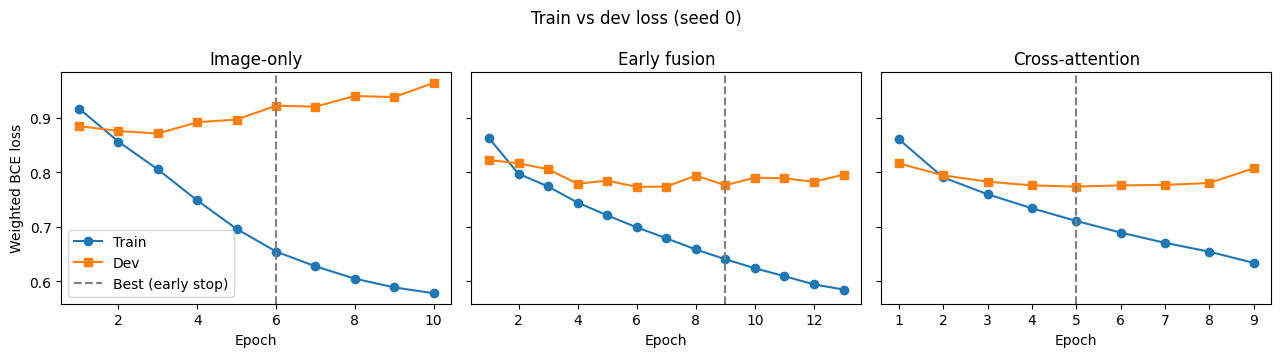

In [12]:
import matplotlib.pyplot as plt
R = pd.DataFrame(results)
y = D['test']['y']
thr = {(r.model, r.seed): r.threshold for r in R.itertuples()}

# 1. Results table (mean ± std over 3 seeds)
order = ['Question-only', 'Image-only', 'Late fusion', 'Early fusion',
         'Cross-attention', 'Gated (no dropout)', 'Gated + modality dropout']
tab = R.groupby('model')[['macro_f1', 'auroc', 'auprc', 'acc', 'train_f1']].agg(['mean', 'std']).round(3).loc[order]
tab.to_csv(f'{SAVE}/results_table.csv'); print(tab)

# 2. Paired bootstrap: gain in macro-F1 over image-only (95% CI)
def mf1(yt, yp):
    tp = ((yt == 1) & yp).sum(); tn = ((yt == 0) & ~yp).sum()
    fp = ((yt == 0) & yp).sum(); fn = ((yt == 1) & ~yp).sum()
    return (2*tp/(2*tp+fp+fn) + 2*tn/(2*tn+fn+fp)) / 2

rng = np.random.default_rng(0); B = 1000; n = len(y)
boots = [rng.integers(0, n, n) for _ in range(B)]
print('\nGain over Image-only (macro-F1, 95% bootstrap CI):')
for m in order[2:]:
    g = []
    for idx in boots:
        g.append(np.mean([mf1(y[idx], test_probs[(m, s)][idx] >= thr[(m, s)]) -
                          mf1(y[idx], test_probs[('Image-only', s)][idx] >= thr[('Image-only', s)])
                          for s in (0, 1, 2)]))
    lo, hi = np.percentile(g, [2.5, 97.5])
    print(f'{m:26s} +{np.mean(g):.3f}  [{lo:.3f}, {hi:.3f}]')

# 3. Overfitting: train vs dev loss curves (seed 0)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a, m in zip(ax, ['Image-only', 'Early fusion', 'Cross-attention']):
    h = pd.DataFrame(histories[(m, 0)])
    a.plot(h.epoch, h.train_loss, 'o-', label='Train')
    a.plot(h.epoch, h.dev_loss, 's-', label='Dev')
    a.axvline(h.dev_auc.idxmax() + 1, ls='--', c='grey', label='Best (early stop)')
    a.set_title(m); a.set_xlabel('Epoch')
ax[0].set_ylabel('Weighted BCE loss'); ax[0].legend()
plt.suptitle('Train vs dev loss (seed 0)'); plt.tight_layout()
plt.savefig(f'{SAVE}/fig_overfitting.png', dpi=200); plt.show()

## 11. Subgroups, gate analysis, latency

                       Subgroup    n  % unanswerable  Question-only  Image-only  Early fusion  Cross-attention  Gated + modality dropout
                  Blurry photos 1398            41.1          0.640       0.717         0.773            0.772                     0.770
                  Medium photos 1397            31.0          0.643       0.670         0.759            0.753                     0.749
                   Sharp photos 1524            24.8          0.663       0.666         0.734            0.744                     0.736
Frequent question (5+ in train) 1700            22.9          0.596       0.719         0.781            0.781                     0.778
    Rare question (<5 in train) 2619            38.0          0.630       0.678         0.743            0.744                     0.740


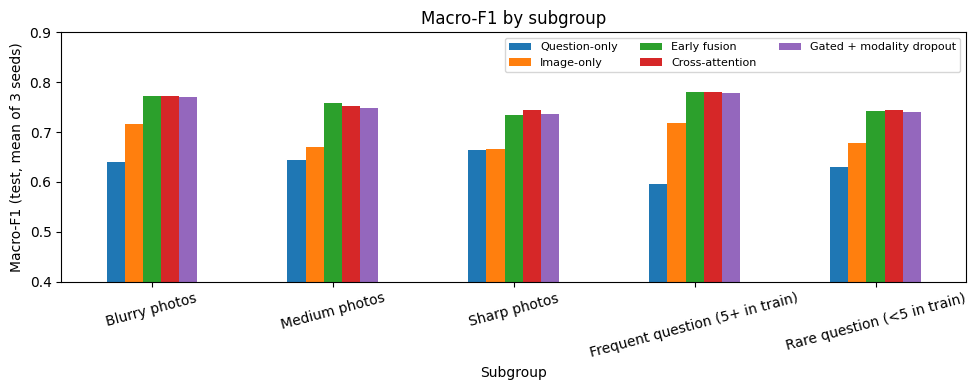


Gate weight on image (mean): {'Blurry': np.float32(0.847), 'Medium': np.float32(0.844), 'Sharp': np.float32(0.84)}
Spearman(gate, sharpness): SignificanceResult(statistic=np.float64(-0.08020322820776304), pvalue=np.float64(1.3069990560030638e-07))

Latency per query: median 95.9 ms, 95th pct 336.7 ms
Params - ViT: 86 M | BERT: 109 M | Cross-attn head: 692 K


In [13]:
from scipy.stats import spearmanr

# 1. Subgroups: image sharpness and question frequency (cut-offs from train)
norm = lambda s: s.str.lower().str.strip().str.rstrip('?').str.strip()
qc = norm(train.question).value_counts()
qcount = norm(test.question).map(qc).fillna(0).values
cuts = np.quantile(train.sharp, [1/3, 2/3])
sg = np.where(test.sharp < cuts[0], 'Blurry', np.where(test.sharp < cuts[1], 'Medium', 'Sharp'))
groups = {'Blurry photos': sg == 'Blurry', 'Medium photos': sg == 'Medium', 'Sharp photos': sg == 'Sharp',
          'Frequent question (5+ in train)': qcount >= 5, 'Rare question (<5 in train)': qcount < 5}
models = ['Question-only', 'Image-only', 'Early fusion', 'Cross-attention', 'Gated + modality dropout']
rows = []
for g, msk in groups.items():
    row = {'Subgroup': g, 'n': int(msk.sum()), '% unanswerable': round(100 * y[msk].mean(), 1)}
    for m in models:
        row[m] = np.mean([mf1(y[msk], test_probs[(m, s)][msk] >= thr[(m, s)]) for s in (0, 1, 2)])
    rows.append(row)
sub = pd.DataFrame(rows).round(3)
sub.to_csv(f'{SAVE}/subgroups.csv', index=False); print(sub.to_string(index=False))

sub.set_index('Subgroup')[models].plot.bar(figsize=(10, 4), rot=15)
plt.ylabel('Macro-F1 (test, mean of 3 seeds)'); plt.ylim(0.4, 0.9)
plt.title('Macro-F1 by subgroup'); plt.legend(fontsize=8, ncol=3); plt.tight_layout()
plt.savefig(f'{SAVE}/fig_subgroups.png', dpi=200); plt.show()

# 2. Gate analysis: does the gate trust blurry photos less?
_, _, _, gm = train_model(Gated, 0)
gm.eval(); zs = []
with torch.no_grad():
    for i in range(0, len(y), 1024):
        gm(D['test']['img'][i:i+1024].float(), D['test']['txt'][i:i+1024].float(), D['test']['mask'][i:i+1024])
        zs.append(gm.last_z.cpu())
z = torch.cat(zs).numpy()
print('\nGate weight on image (mean):', {g: round(z[sg == g].mean(), 3) for g in ['Blurry', 'Medium', 'Sharp']})
print('Spearman(gate, sharpness):', spearmanr(z, test.sharp))

# 3. End-to-end speed per query on T4 (photo + question -> probability)
_, _, _, cm = train_model(CrossAttn, 0, lr=3e-4); cm.eval()

@torch.no_grad()
def predict_one(path, question):
    img = ImageOps.exif_transpose(Image.open(path)).convert('RGB')
    h = vit(pixel_values=proc(img, return_tensors='pt')['pixel_values'].to(device).half()).last_hidden_state
    grid = h[:, 1:].reshape(-1, 14, 14, 768).permute(0, 3, 1, 2)
    im = torch.cat([h[:, :1], F.avg_pool2d(grid, 2).flatten(2).transpose(1, 2)], 1)
    t = tok([question], padding='max_length', truncation=True, max_length=32, return_tensors='pt').to(device)
    return torch.sigmoid(cm(im.float(), bert(**t).last_hidden_state.float(), t['attention_mask'])).item()

p0, q0 = test.path.iloc[0], test.question.iloc[0]
for _ in range(10): predict_one(p0, q0)                     # warm-up
ts = []
for i in range(100):
    torch.cuda.synchronize(); t0 = time.perf_counter()
    predict_one(test.path.iloc[i], test.question.iloc[i])
    torch.cuda.synchronize(); ts.append((time.perf_counter() - t0) * 1000)
print(f'\nLatency per query: median {np.median(ts):.1f} ms, 95th pct {np.percentile(ts, 95):.1f} ms')
print('Params - ViT:', sum(p.numel() for p in vit.parameters()) // 10**6, 'M | BERT:',
      sum(p.numel() for p in bert.parameters()) // 10**6, 'M | Cross-attn head:',
      sum(p.numel() for p in cm.parameters()) // 1000, 'K')

## 12. CLIP reference

In [15]:
from transformers import CLIPModel, CLIPProcessor
clip  = CLIPModel.from_pretrained('openai/clip-vit-base-patch16').to(device).eval().half()
cproc = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch16')
as_t = lambda o: o if torch.is_tensor(o) else o.pooler_output

class CImgs(Dataset):
    def __init__(s, paths): s.p = list(paths)
    def __len__(s): return len(s.p)
    def __getitem__(s, i):
        img = ImageOps.exif_transpose(Image.open(s.p[i])).convert('RGB')
        return cproc(images=img, return_tensors='pt')['pixel_values'][0]

@torch.no_grad()
def clip_feats(d):
    I = [as_t(clip.get_image_features(pixel_values=x.to(device).half())).float().cpu()
         for x in tqdm(DataLoader(CImgs(d.path), batch_size=64, num_workers=2))]
    qs, T = list(d.question), []
    for i in range(0, len(qs), 256):
        t = cproc(text=qs[i:i+256], padding=True, truncation=True, return_tensors='pt').to(device)
        T.append(as_t(clip.get_text_features(**t)).float().cpu())
    return F.normalize(torch.cat(I), dim=-1), F.normalize(torch.cat(T), dim=-1)

D_clip = {}
for name, d in [('train', train), ('dev', dev), ('test', test)]:
    I, T = clip_feats(d)
    D_clip[name] = dict(img=I[:, None].to(device), txt=T[:, None].to(device),
                        mask=torch.ones(len(d), 1, dtype=torch.long, device=device),
                        soft=D[name]['soft'], y=D[name]['y'])

class ClipMLP(nn.Module):                     # same early-fusion head, on CLIP embeddings
    def __init__(s): super().__init__(); s.f = mlp(1024)
    def forward(s, img, txt, mask): return s.f(torch.cat([img[:, 0], txt[:, 0]], -1)).squeeze(-1)

D_main, D = D, D_clip
run('CLIP reference', ClipMLP)
D = D_main                                    # switch back to ViT/BERT features

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

100%|██████████| 68/68 [02:01<00:00,  1.79s/it]


CLIP reference
      macro_f1  auroc  auprc  train_f1  epochs   secs
mean     0.801  0.900  0.805     0.887  10.333  3.367
std      0.003  0.002  0.004     0.020   2.309  0.473


## 13. Model sizes

In [2]:
print(pd.DataFrame(results).groupby('model')['params'].first())

Mounted at /content/drive
model
CLIP reference              264705.0
Cross-attention             692097.0
Early fusion                396801.0
Gated (no dropout)          853761.0
Gated + modality dropout    853761.0
Image-only                  198657.0
Late fusion                      NaN
Question-only               198657.0
Name: params, dtype: float64


## 14. Pipeline figure

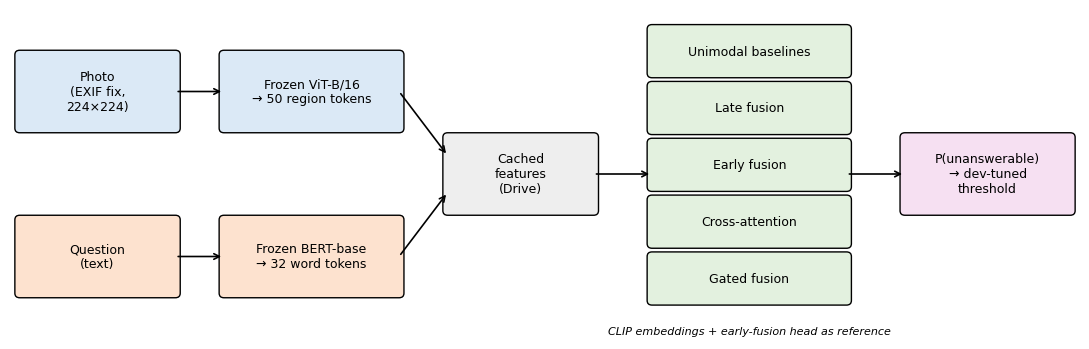

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 3.6)); ax.axis('off')
ax.set_xlim(0, 11); ax.set_ylim(0, 3.6)

def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05', fc=color, ec='black'))
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=9)

def arrow(x1, y1, x2, y2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->', lw=1.2))

box(0.1, 2.3, 1.6, 0.8, 'Photo\n(EXIF fix,\n224×224)', '#dbe9f6')
box(0.1, 0.5, 1.6, 0.8, 'Question\n(text)', '#fde2cf')
box(2.2, 2.3, 1.8, 0.8, 'Frozen ViT-B/16\n→ 50 region tokens', '#dbe9f6')
box(2.2, 0.5, 1.8, 0.8, 'Frozen BERT-base\n→ 32 word tokens', '#fde2cf')
box(4.5, 1.4, 1.5, 0.8, 'Cached\nfeatures\n(Drive)', '#eeeeee')
models = ['Unimodal baselines', 'Late fusion', 'Early fusion', 'Cross-attention', 'Gated fusion']
for i, m in enumerate(models):
    box(6.6, 2.9 - i*0.62, 2.0, 0.48, m, '#e3f1df')
box(9.2, 1.4, 1.7, 0.8, 'P(unanswerable)\n→ dev-tuned\nthreshold', '#f6e0f2')

arrow(1.7, 2.7, 2.2, 2.7); arrow(1.7, 0.9, 2.2, 0.9)
arrow(4.0, 2.7, 4.5, 2.0); arrow(4.0, 0.9, 4.5, 1.6)
arrow(6.0, 1.8, 6.6, 1.8); arrow(8.6, 1.8, 9.2, 1.8)
ax.text(7.6, 0.05, 'CLIP embeddings + early-fusion head as reference', ha='center', fontsize=8, style='italic')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/vizwiz/fig_pipeline.png', dpi=200, bbox_inches='tight')
plt.show()